In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from IPython.display import display


RAIZ = Path.cwd().resolve()

if not (RAIZ / "laboratorio.py").exists():
    RAIZ = RAIZ.parent


ARQUIVO = (
    RAIZ
    / "datasets"
    / "dataset_experimental.csv"
)

dataset = pd.read_csv(ARQUIVO)

print("Linhas:", len(dataset))
print("Ensaios:", dataset["ensaio"].nunique())

Linhas: 2160
Ensaios: 12


In [2]:
COLUNAS_ML = [
    "taxa_requisicoes",
    "latencia_ms",
    "latencia_disponivel"
]
COLUNAS_CONTINUAS = [
    "taxa_requisicoes",
    "latencia_ms"
]
COLUNAS_BINARIAS = [
    "latencia_disponivel"
]

In [3]:
X_treino = (
    dataset.loc[
        dataset["split"] == "treino",
        COLUNAS_ML
    ]
    .copy()
)

X_validacao = (
    dataset.loc[
        dataset["split"] == "validacao",
        COLUNAS_ML
    ]
    .copy()
)

X_teste = (
    dataset.loc[
        dataset["split"] == "teste",
        COLUNAS_ML
    ]
    .copy()
)


print("Treino:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

Treino: (1080, 3)
Validação: (540, 3)
Teste: (540, 3)


In [4]:
COLUNAS_AVALIACAO = [
    "label",
    "condicao",
    "nivel_carga",
    "manutencao_legitima",
    "janela_transicao",
    "seed",
    "ensaio",
    "janela"
]


avaliacao_treino = dataset.loc[
    dataset["split"] == "treino",
    COLUNAS_AVALIACAO
].copy()

avaliacao_validacao = dataset.loc[
    dataset["split"] == "validacao",
    COLUNAS_AVALIACAO
].copy()

avaliacao_teste = dataset.loc[
    dataset["split"] == "teste",
    COLUNAS_AVALIACAO
].copy()

mediana_latencia_treino = (
    X_treino["latencia_ms"]
    .median()
)

print(
    "Mediana da latência no treino:",
    round(mediana_latencia_treino, 4)
)

Mediana da latência no treino: 2.4758


In [5]:
for X in [
    X_treino,
    X_validacao,
    X_teste
]:

    X["latencia_ms"] = (
        X["latencia_ms"]
        .fillna(
            mediana_latencia_treino
        )
    )

print(
    "NaN treino:",
    X_treino.isna().sum().sum()
)

print(
    "NaN validação:",
    X_validacao.isna().sum().sum()
)

print(
    "NaN teste:",
    X_teste.isna().sum().sum()
)

NaN treino: 0
NaN validação: 0
NaN teste: 0


In [6]:
standard_scaler = StandardScaler()

robust_scaler = RobustScaler()


standard_scaler.fit(
    X_treino[
        COLUNAS_CONTINUAS
    ]
)

robust_scaler.fit(
    X_treino[
        COLUNAS_CONTINUAS
    ]
)

def transformar_dados(
    X,
    scaler
):

    X_transformado = X.copy()

    X_transformado[
        COLUNAS_CONTINUAS
    ] = scaler.transform(
        X[
            COLUNAS_CONTINUAS
        ]
    )

    return X_transformado

In [7]:
X_treino_standard = transformar_dados(
    X_treino,
    standard_scaler
)

X_validacao_standard = transformar_dados(
    X_validacao,
    standard_scaler
)

X_teste_standard = transformar_dados(
    X_teste,
    standard_scaler
)



X_treino_robust = transformar_dados(
    X_treino,
    robust_scaler
)

X_validacao_robust = transformar_dados(
    X_validacao,
    robust_scaler
)

X_teste_robust = transformar_dados(
    X_teste,
    robust_scaler
)


In [8]:
print("STANDARD SCALER")

display(
    X_treino_standard
    .describe()
    .round(3)
)

STANDARD SCALER


,taxa_requisicoes,latencia_ms,latencia_disponivel
count,1080.000,1080.000,1080.000
mean,0.000,0.000,0.919
std,1.000,1.000,0.274
min,-0.972,-2.545,0.000
25%,-0.669,-0.626,1.000
50%,-0.669,0.083,1.000
75%,0.544,0.595,1.000
max,2.667,3.930,1.000


In [9]:
print("ROBUST SCALER")

display(
    X_treino_robust
    .describe()
    .round(3)
)

ROBUST SCALER


,taxa_requisicoes,latencia_ms,latencia_disponivel
count,1080.000,1080.000,1080.000
mean,0.552,-0.068,0.919
std,0.825,0.820,0.274
min,-0.250,-2.153,0.000
25%,0.000,-0.581,1.000
50%,0.000,0.000,1.000
75%,1.000,0.419,1.000
max,2.750,3.151,1.000


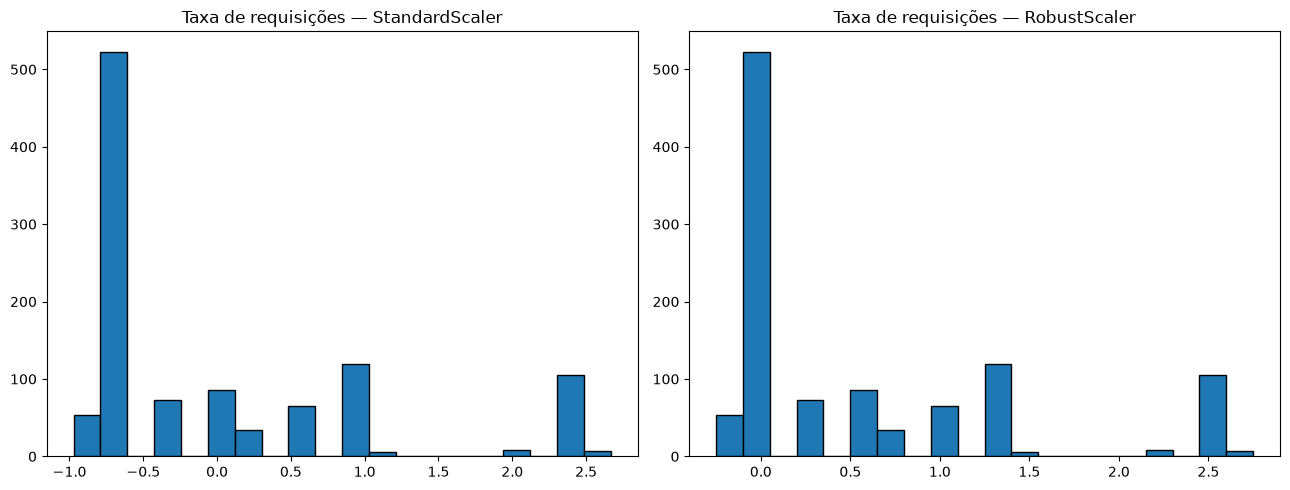

In [10]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

axes[0].hist(
    X_treino_standard[
        "taxa_requisicoes"
    ],
    bins=20,
    edgecolor="black"
)

axes[0].set_title(
    "Taxa de requisições — StandardScaler"
)

axes[1].hist(
    X_treino_robust[
        "taxa_requisicoes"
    ],
    bins=20,
    edgecolor="black"
)

axes[1].set_title(
    "Taxa de requisições — RobustScaler"
)

plt.tight_layout()
plt.show()

In [11]:
VALORES_K = range(
    2,
    11
)

def avaliar_kmeans(
    X,
    valores_k
):

    resultados = []

    for k in valores_k:

        modelo = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        clusters = modelo.fit_predict(
            X
        )

        inercia = modelo.inertia_

        silhouette = silhouette_score(
            X,
            clusters
        )

        resultados.append({
            "k": k,
            "inercia": inercia,
            "silhouette": silhouette
        })

    return pd.DataFrame(
        resultados
    )

In [12]:
resultado_standard = avaliar_kmeans(
    X_treino_standard,
    VALORES_K
)

display(
    resultado_standard.round(4)
)

,k,inercia,silhouette
0,2,1418.0505,0.4141
1,3,888.0951,0.4176
2,4,687.9316,0.4314
3,5,530.7902,0.4101
4,6,445.3558,0.4147
5,7,381.1099,0.4836
6,8,311.8652,0.4828
7,9,261.4108,0.4816
8,10,223.2540,0.4813


In [13]:
resultado_robust = avaliar_kmeans(
    X_treino_robust,
    VALORES_K
)

display(
    resultado_robust.round(4)
)

,k,inercia,silhouette
0,2,980.2847,0.4094
1,3,623.9460,0.4116
2,4,487.5737,0.4247
3,5,381.3235,0.4010
4,6,320.0876,0.4709
5,7,261.9907,0.4813
6,8,215.2995,0.4824
7,9,181.2770,0.4806
8,10,155.4916,0.4803


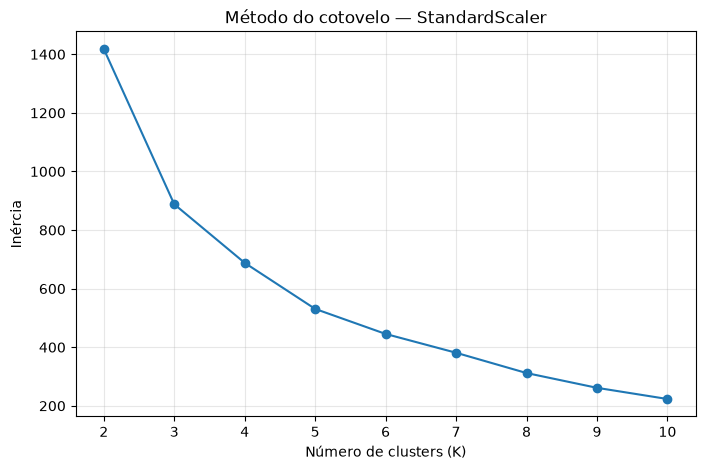

In [14]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    resultado_standard["k"],
    resultado_standard["inercia"],
    marker="o"
)

ax.set_title(
    "Método do cotovelo — StandardScaler"
)

ax.set_xlabel(
    "Número de clusters (K)"
)

ax.set_ylabel(
    "Inércia"
)

ax.grid(alpha=0.3)

plt.show()

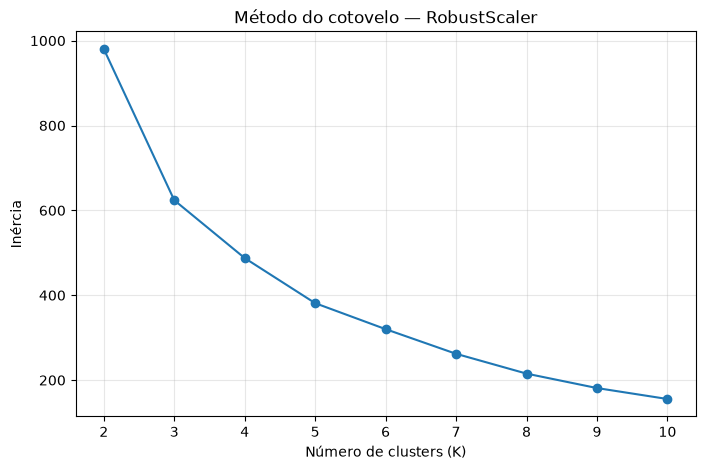

In [15]:
fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    resultado_robust["k"],
    resultado_robust["inercia"],
    marker="o"
)

ax.set_title(
    "Método do cotovelo — RobustScaler"
)

ax.set_xlabel(
    "Número de clusters (K)"
)

ax.set_ylabel(
    "Inércia"
)

ax.grid(alpha=0.3)

plt.show()

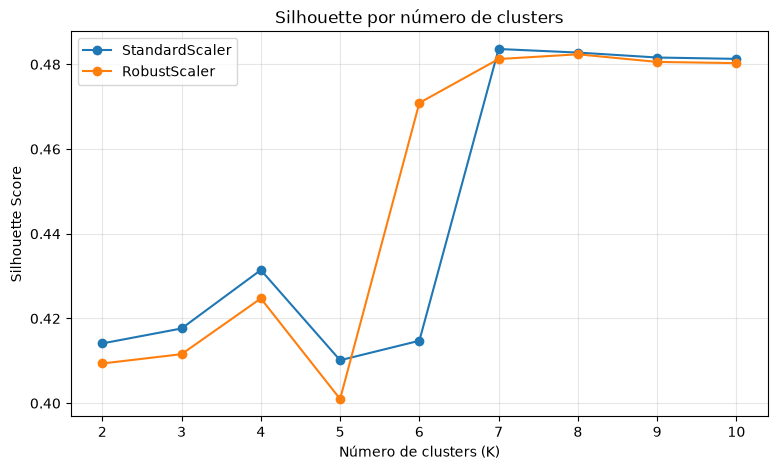

In [16]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    resultado_standard["k"],
    resultado_standard["silhouette"],
    marker="o",
    label="StandardScaler"
)

ax.plot(
    resultado_robust["k"],
    resultado_robust["silhouette"],
    marker="o",
    label="RobustScaler"
)

ax.set_title(
    "Silhouette por número de clusters"
)

ax.set_xlabel(
    "Número de clusters (K)"
)

ax.set_ylabel(
    "Silhouette Score"
)

ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [17]:
def sugerir_cotovelo(
    tabela
):

    x = tabela["k"].to_numpy(
        dtype=float
    )

    y = tabela["inercia"].to_numpy(
        dtype=float
    )

    x_norm = (
        (x - x.min())
        / (x.max() - x.min())
    )

    y_norm = (
        (y - y.min())
        / (y.max() - y.min())
    )

    x1 = x_norm[0]
    y1 = y_norm[0]

    x2 = x_norm[-1]
    y2 = y_norm[-1]

    numerador = np.abs(
        (y2 - y1) * x_norm
        - (x2 - x1) * y_norm
        + x2 * y1
        - y2 * x1
    )

    denominador = np.sqrt(
        (y2 - y1) ** 2
        + (x2 - x1) ** 2
    )

    distancias = (
        numerador / denominador
    )

    indice = np.argmax(
        distancias
    )

    return int(
        x[indice]
    )

In [18]:
k_standard = sugerir_cotovelo(
    resultado_standard
)

k_robust = sugerir_cotovelo(
    resultado_robust
)

print(
    "Cotovelo sugerido StandardScaler:",
    k_standard
)

print(
    "Cotovelo sugerido RobustScaler:",
    k_robust
)

Cotovelo sugerido StandardScaler: 5
Cotovelo sugerido RobustScaler: 5


In [19]:
comparacao_scalers = pd.DataFrame({
    "Scaler": [
        "StandardScaler",
        "RobustScaler"
    ],

    "K_cotovelo": [
        k_standard,
        k_robust
    ],

    "Melhor_K_silhouette": [
        int(
            resultado_standard.loc[
                resultado_standard[
                    "silhouette"
                ].idxmax(),
                "k"
            ]
        ),

        int(
            resultado_robust.loc[
                resultado_robust[
                    "silhouette"
                ].idxmax(),
                "k"
            ]
        )
    ],

    "Melhor_silhouette": [
        resultado_standard[
            "silhouette"
        ].max(),

        resultado_robust[
            "silhouette"
        ].max()
    ]
})

display(
    comparacao_scalers.round(4)
)

,Scaler,K_cotovelo,Melhor_K_silhouette,Melhor_silhouette
0,StandardScaler,5,7,0.4836
1,RobustScaler,5,8,0.4824
